<a href="https://colab.research.google.com/github/Sankar-s-r/Deepfake_Detection/blob/multisource/FADID_PV_v2_multisource.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FADID-PV v2: Multi-Source Deepfake Detection (GAN + Face-Swap + Diffusion)

A corrected, multi-dataset rebuild of `FADID_PV_Lite_140k`. What changed and why:

| Area | v1 problem | v2 fix |
|---|---|---|
| Data | one generator (StyleGAN) | pluggable **source registry**: image folders + videos, any number of generators |
| Preprocessing | fixed eye coordinates, only valid for FFHQ-aligned images | every source goes through the **same** face detect + 5-point align + uniform JPEG re-encode |
| Splits | dataset split only | **group-aware** splits (per video / identity) + **leave-generator-out** zero-day split |
| Frequency masks | wrong bands (corner masks) | **radial** masks on GPU; always-on high-pass branch (same at train and test) |
| Contrastive loss | positives/diagonal bug | fixed SupCon |
| Classifier | L2-normalised input, no scale | classifier on raw fused features; normalised copy only for SupCon |
| Backbone | only LayerNorm trainable (0.09%) | last-K blocks unfrozen with lower LR, CLIP ViT-B/16 default |
| DID | adversary on reals too, dead branch | adversary on **fakes only**, decorrelation loss on the second branch |
| Eval | one AUC, last-epoch weights | best checkpoint, **per-generator / per-source AUC**, zero-day AUC, robustness tests |

Run top to bottom. Section 3 (source registry) is the only place you must edit.

## 1. Setup

In [3]:
!pip install -q timm scikit-learn pandas matplotlib tqdm kaggle opencv-python-headless huggingface_hub

import os, glob, re, json, math, random, hashlib, shutil, threading
from dataclasses import dataclass, field
from typing import Optional, Tuple, Dict, List
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
cv2.setNumThreads(1)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import timm

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 2. Config

* `holdout_generators`: fake generators that are **never** seen in training or validation. They form the zero-day test.
  Start with `[]` for a first sanity run, then hold one out at a time (leave-one-generator-out).
* `max_per_item`: caps images/videos per source entry so one huge dataset does not dominate.

In [4]:
@dataclass
class Config:
    # paths
    work_dir: str = "/content/work"                 # all processed data + manifest live here
    processed_dir: str = "/content/work/processed"  # aligned 256x256 JPEGs
    manifest_csv: str = "/content/work/manifest.csv"

    # preprocessing (identical for every source)
    aligned_size: int = 256
    jpeg_quality: int = 95            # uniform re-encode: removes the container/format shortcut
    frames_per_video: int = 8
    min_face_score: float = 0.6
    preprocess_workers: int = 4

    # splitting
    val_frac: float = 0.1
    test_frac: float = 0.1
    holdout_generators: Tuple[str, ...] = ()        # e.g. ("Deepfakes",) for a zero-day run

    # model
    backbone_name: str = "vit_base_patch16_clip_224.openai"   # CLIP ViT-B/16; use "vit_small_patch16_224" for speed
    input_size: int = 224
    unfreeze_last_blocks: int = 4
    use_eye_branch: bool = True
    eye_crop_size: int = 64
    did_hidden: int = 256
    did_out: int = 128
    fusion_dim: int = 128

    # frequency
    hp_cutoff: float = 0.12           # radial cutoff (0..1) for the always-on high-pass branch
    hp_gain: float = 4.0              # amplifies the (small) high-pass residual before the backbone
    band_drop_prob: float = 0.3       # train-time spectral band-drop augmentation on the spatial view

    # degradation augmentation (train only)
    degradation_prob: float = 0.5
    max_degradation_ops: int = 2

    # loss weights
    alpha_adv: float = 0.1            # generator-adversarial (fakes only); set 0 to ablate
    beta_eye: float = 0.2
    gamma_metric: float = 0.3
    metric_temperature: float = 0.1
    grl_lambda: float = 1.0
    decor_weight: float = 0.05

    # optimisation
    batch_size: int = 32
    num_workers: int = 2
    lr_head: float = 3e-4
    lr_backbone: float = 2e-5
    weight_decay: float = 1e-2
    epochs: int = 8
    warmup_frac: float = 0.05
    grad_clip: float = 1.0
    amp: bool = True
    max_train_samples: Optional[int] = None    # set e.g. 4000 for a quick end-to-end check

cfg = Config()
os.makedirs(cfg.work_dir, exist_ok=True); os.makedirs(cfg.processed_dir, exist_ok=True)

## 3. Source registry (edit this)

Every dataset is a `Source` made of `Item`s. An `Item` is a folder pattern + a label (0 real / 1 fake) +
a **generator name** + whether files are images or videos.

**Rules that matter for generalisation**
1. Include reals from several places (FFHQ, CelebA-HQ, FF++ originals, Celeb-DF reals, DFDC reals ...). Otherwise "which dataset" becomes the shortcut.
2. Give each fake method its own `generator` string (`Deepfakes`, `Face2Face`, `StyleGAN2`, `MyGAN`, `StableDiffusion` ...). Per-generator metrics and leave-one-out depend on it.
3. `group_regex` (optional) extracts a group id (video / identity) from the file name so that no group is split across train/val/test.

Download helpers for Kaggle and Hugging Face are in the next cell. Datasets with licence forms
(FaceForensics++, Celeb-DF, DFDC, DeeperForensics) must be requested from their owners; point `root` at wherever you put them.

In [2]:
# 1. Download Kaggle datasets
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces -p /content/140k --unzip
!kaggle datasets download -d reubensuju/celeb-df-v2 -p /content/celebdf --unzip

# 2. Download DeepFakeFace from Hugging Face (Corrected with ! prefix)
!python -c "from huggingface_hub import snapshot_download; snapshot_download(repo_id='OpenRL/DeepFakeFace', repo_type='dataset', local_dir='/content/dff')"

# 3. Unzip the diffusion dataset archives
!unzip -q /content/dff/inpainting.zip -d /content/dff/
!unzip -q /content/dff/insight.zip -d /content/dff/
!unzip -q /content/dff/text2img.zip -d /content/dff/
!unzip -q /content/dff/wiki.zip -d /content/dff/

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:54<00:00, 74.2MB/s]

Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
License(s): unknown
100% 9.29G/9.29G [01:39<00:00, 100MB/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0% 0/10 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):   0% 0.00/330k [00:00<?, ?B/s]          
Reconstructing (incomplete total...):   0% 0.00/2.16G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/2.16G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/2.16G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/2.16G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/2.16G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0

In [5]:
from dataclasses import dataclass
from typing import List, Optional, Dict

@dataclass
class Item:
    pattern: str                 # glob pattern
    label: int                   # 0 real, 1 fake
    generator: str               # "real" for label 0, method name for fakes
    kind: str = "image"          # "image" or "video"
    max_items: Optional[int] = None
    group_regex: Optional[str] = None   # capture group for group/identity id

@dataclass
class Source:
    name: str
    items: List[Item]
    predefined_split: Optional[Dict[str, str]] = None

SOURCES: List[Source] = [
    # ---- GAN faces: FFHQ vs StyleGAN ----
    Source("140k", [
        Item("/content/140k/real_vs_fake/real-vs-fake/train/real/*", 0, "real_ffhq", max_items=6000),
        Item("/content/140k/real_vs_fake/real-vs-fake/train/fake/*", 1, "StyleGAN", max_items=6000),
    ]),
    # ---- Celeb-DF v2 ----
    Source("celebdf", [
         Item("/content/celebdf/Celeb-real/*.mp4", 0, "real_celebdf", "video"),
         Item("/content/celebdf/Celeb-synthesis/*.mp4", 1, "CelebDF", "video", group_regex=r"^id(\d+)_"),
    ]),
    # ---- Diffusion faces ----
    Source("dff", [
        Item("/content/dff/wiki/**/*.jpg", 0, "real_wiki", max_items=5000),
        Item("/content/dff/text2img/**/*.jpg", 1, "SD_text2img", max_items=5000),
        Item("/content/dff/inpainting/**/*.jpg", 1, "SD_inpainting", max_items=5000),
        Item("/content/dff/insight/**/*.jpg", 1, "InsightFace_swap", max_items=5000),
    ]),
]


## 4. Unified face preprocessing

All sources go through the same pipeline so the detector cannot learn dataset-specific framing or format:

1. read image / sample `frames_per_video` frames evenly from each video
2. detect the largest face (OpenCV **YuNet**, 5 landmarks; falls back to a Haar cascade if the model cannot be downloaded)
3. similarity-align the 5 landmarks to a fixed template, output `aligned_size` x `aligned_size`
4. save as JPEG at one fixed quality for **every** image (real and fake)

Because eyes now land at the same coordinates in every source, fixed-coordinate eye crops are valid everywhere.

In [6]:
# ArcFace 112x112 5-point template (image-left eye, image-right eye, nose, image-left mouth, image-right mouth)
_ARC = np.array([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                 [41.5493, 92.3655], [70.7299, 92.2041]], dtype=np.float32)

def make_template(size):
    s = size / 128.0            # 128 -> leaves a margin around the 112 template
    return _ARC * s + (size - 112 * s) / 2.0

TEMPLATE = make_template(cfg.aligned_size)
# eye centres in the aligned frame (used for eye crops everywhere)
EYE_L = TEMPLATE[0].copy(); EYE_R = TEMPLATE[1].copy()

YUNET_URLS = [
    "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
]
YUNET_PATH = os.path.join(cfg.work_dir, "yunet.onnx")

def ensure_yunet():
    if os.path.exists(YUNET_PATH) and os.path.getsize(YUNET_PATH) > 100_000:
        return True
    for u in YUNET_URLS:
        os.system(f"curl -sL -o {YUNET_PATH} '{u}'")
        if os.path.exists(YUNET_PATH) and os.path.getsize(YUNET_PATH) > 100_000:
            return True
    print("WARNING: YuNet unavailable, falling back to Haar cascade (lower quality alignment).")
    return False

HAVE_YUNET = ensure_yunet()
_tls = threading.local()

def _detector():
    if not hasattr(_tls, "det"):
        if HAVE_YUNET:
            _tls.det = cv2.FaceDetectorYN.create(YUNET_PATH, "", (320, 320), cfg.min_face_score, 0.3, 5000)
        else:
            _tls.det = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    return _tls.det

def detect_landmarks(img_bgr):
    # returns 5x2 float32 landmarks of the largest face in full-resolution coordinates, or None
    h, w = img_bgr.shape[:2]
    scale = 640.0 / max(h, w) if max(h, w) > 640 else 1.0
    small = cv2.resize(img_bgr, (int(w * scale), int(h * scale))) if scale != 1.0 else img_bgr
    det = _detector()
    if HAVE_YUNET:
        det.setInputSize((small.shape[1], small.shape[0]))
        _, faces = det.detect(small)
        if faces is None or len(faces) == 0:
            return None
        f = max(faces, key=lambda r: r[2] * r[3])
        pts = np.array(f[4:14], dtype=np.float32).reshape(5, 2)   # re, le, nose, rcm, lcm
        return pts / scale
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    rects = det.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(rects) == 0:
        return None
    x, y, ww, hh = max(rects, key=lambda r: r[2] * r[3])
    # crude landmark guess from the box (Haar has no landmarks)
    pts = np.array([[x + .30 * ww, y + .38 * hh], [x + .70 * ww, y + .38 * hh], [x + .50 * ww, y + .58 * hh],
                    [x + .35 * ww, y + .78 * hh], [x + .65 * ww, y + .78 * hh]], dtype=np.float32)
    return pts / scale

def align_face(img_bgr, size=None):
    size = size or cfg.aligned_size
    pts = detect_landmarks(img_bgr)
    if pts is None:
        return None
    M, _ = cv2.estimateAffinePartial2D(pts, make_template(size), method=cv2.LMEDS)
    if M is None:
        return None
    return cv2.warpAffine(img_bgr, M, (size, size), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def read_video_frames(path, n):
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total > 0:
        for idx in np.linspace(0, max(total - 1, 0), n + 2)[1:-1].astype(int):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, fr = cap.read()
            if ok:
                frames.append(fr)
    if not frames:                       # seek failed: read sequentially
        cap.release(); cap = cv2.VideoCapture(path)
        allf = []
        while True:
            ok, fr = cap.read()
            if not ok: break
            allf.append(fr)
        if allf:
            frames = [allf[i] for i in np.linspace(0, len(allf) - 1, min(n, len(allf))).astype(int)]
    cap.release()
    return frames

def _stable_id(path):
    return hashlib.md5(path.encode()).hexdigest()[:10]

def process_one(task):
    src_name, item, path = task
    out_rows = []
    group = None
    stem = os.path.splitext(os.path.basename(path))[0]
    if item.group_regex:
        m = re.search(item.group_regex, stem)
        group = m.group(1) if m else stem
    else:
        group = stem
    group = f"{src_name}:{group}"
    try:
        if item.kind == "video":
            imgs = read_video_frames(path, cfg.frames_per_video)
        else:
            im = cv2.imread(path)
            imgs = [im] if im is not None else []
        for k, im in enumerate(imgs):
            face = align_face(im)
            if face is None:
                continue
            out = os.path.join(cfg.processed_dir, src_name, f"{item.generator}_{_stable_id(path)}_{k}.jpg")
            os.makedirs(os.path.dirname(out), exist_ok=True)
            cv2.imwrite(out, face, [int(cv2.IMWRITE_JPEG_QUALITY), cfg.jpeg_quality])
            out_rows.append({"image_path": out, "label": item.label, "generator": item.generator,
                             "dataset_name": src_name, "group_id": group,
                             "source_file": path})
    except Exception as e:
        pass
    return out_rows

def preprocess_sources(sources):
    rows = []
    for src in sources:
        tasks = []
        for item in src.items:
            files = sorted(glob.glob(item.pattern, recursive=True))
            files = [f for f in files if os.path.isfile(f)]
            if not files:
                print(f"WARNING [{src.name}] nothing matched {item.pattern}")
                continue
            if item.max_items is not None and len(files) > item.max_items:
                random.Random(SEED).shuffle(files); files = files[:item.max_items]
            tasks += [(src.name, item, f) for f in files]
        print(f"[{src.name}] {len(tasks)} files to process")
        with ThreadPoolExecutor(cfg.preprocess_workers) as ex:
            for r in tqdm(ex.map(process_one, tasks), total=len(tasks), desc=src.name):
                rows += r
    return pd.DataFrame(rows)

if os.path.exists(cfg.manifest_csv):
    print("Manifest exists -> skipping preprocessing. Delete it to rebuild.")
    raw_df = pd.read_csv(cfg.manifest_csv)
else:
    raw_df = preprocess_sources(SOURCES)
    raw_df.to_csv(cfg.manifest_csv, index=False)
print(raw_df.groupby(["dataset_name", "generator", "label"]).size())

[140k] 12000 files to process


140k:   0%|          | 0/12000 [00:00<?, ?it/s]

[celebdf] 6229 files to process


celebdf:   0%|          | 0/6229 [00:00<?, ?it/s]

[dff] 20000 files to process


dff:   0%|          | 0/20000 [00:00<?, ?it/s]

dataset_name  generator         label
140k          StyleGAN          1         6000
              real_ffhq         0         6000
celebdf       CelebDF           1        45112
              real_celebdf      0         4712
dff           InsightFace_swap  1         4918
              SD_inpainting     1         4938
              SD_text2img       1         4955
              real_wiki         0         4947
dtype: int64


## 5. Group-aware splits + leave-generator-out

* Every group (video id / identity / single image) lands in exactly **one** of `train / val / test`, per dataset, so no video leaks across splits.
* Fakes from `cfg.holdout_generators` go to a separate `holdout` split and are **never** used for training, validation or threshold selection. This is the zero-day test.
* For FaceForensics++ use the official split JSONs (`ffpp_predefined_split`) via `Source.predefined_split` instead of random group splits.

In [7]:
def make_splits(df, cfg, sources=SOURCES):
    df = df.copy().reset_index(drop=True)
    holdout = set(cfg.holdout_generators)
    predef = {f"{s.name}:{k}": v for s in sources if s.predefined_split for k, v in s.predefined_split.items()}
    df["split"] = ""
    is_hold = (df.label == 1) & df.generator.isin(holdout)
    df.loc[is_hold, "split"] = "holdout"
    rng = random.Random(SEED)
    pool = df[~is_hold]
    for ds_name, sub in pool.groupby("dataset_name"):
        groups = sorted(sub.group_id.unique())
        rng.shuffle(groups)
        n = len(groups)
        n_test = int(round(n * cfg.test_frac)); n_val = int(round(n * cfg.val_frac))
        gsplit = {}
        for i, g in enumerate(groups):
            gsplit[g] = "test" if i < n_test else ("val" if i < n_test + n_val else "train")
        for g in groups:
            if g in predef:
                gsplit[g] = predef[g]
        df.loc[sub.index, "split"] = sub.group_id.map(gsplit).values
    return df

def build_gen_index(train_df):
    gens = sorted(train_df[train_df.label == 1].generator.unique())
    return {g: i for i, g in enumerate(gens)}

def make_sampler(train_df):
    # balance every (label, generator) cell, then equalise total real vs total fake mass
    cell = train_df.groupby(["label", "generator"]).generator.transform("size").values.astype(np.float64)
    w = 1.0 / cell
    y = train_df.label.values
    w[y == 0] *= w[y == 1].sum() / max(w[y == 0].sum(), 1e-12)
    return WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(train_df), replacement=True)

## 6. Dataset and augmentation

Images are already aligned 256x256 JPEGs. Training uses horizontal flip, compound degradation (JPEG / resize / blur / noise) and a **random crop** to 224
(no resampling, so artifact statistics are preserved); eval uses a centre crop. Eye crops come from the fixed template positions, which are valid for every source after alignment.

In [8]:
def cyclic_jpeg(img, quality_range=(30, 90)):
    q = random.randint(*quality_range)
    ok, enc = cv2.imencode(".jpg", img, [int(cv2.IMWRITE_JPEG_QUALITY), q])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else img

def resolution_roundtrip(img, min_scale=0.4, max_scale=0.9):
    h, w = img.shape[:2]
    s = random.uniform(min_scale, max_scale)
    small = cv2.resize(img, (max(8, int(w * s)), max(8, int(h * s))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def gaussian_blur(img):
    k = random.choice([3, 5])
    return cv2.GaussianBlur(img, (k, k), 0)

def gaussian_noise(img):
    sigma = random.uniform(2, 8)
    n = np.random.randn(*img.shape).astype(np.float32) * sigma
    return np.clip(img.astype(np.float32) + n, 0, 255).astype(np.uint8)

DEGRADATIONS = [cyclic_jpeg, resolution_roundtrip, gaussian_blur, gaussian_noise]

def apply_compound_degradation(img, cfg):
    if random.random() > cfg.degradation_prob:
        return img
    for op in random.sample(DEGRADATIONS, random.randint(1, cfg.max_degradation_ops)):
        img = op(img)
    return img

def crop_eye(img, center, size):
    S = img.shape[0]; half = size // 2
    cx, cy = int(round(center[0])), int(round(center[1]))
    x0 = max(0, min(S - size, cx - half)); y0 = max(0, min(S - size, cy - half))
    return img[y0:y0 + size, x0:x0 + size]

def _u8(a):
    return torch.from_numpy(np.ascontiguousarray(a.transpose(2, 0, 1)))

def sample_from_aligned(img_bgr, cfg, train, eval_degrade=None):
    # shared by training, evaluation and inference so the pipelines cannot drift apart
    if img_bgr.shape[:2] != (cfg.aligned_size, cfg.aligned_size):
        img_bgr = cv2.resize(img_bgr, (cfg.aligned_size, cfg.aligned_size))
    if train:
        if random.random() < 0.5:
            img_bgr = img_bgr[:, ::-1]
        img_bgr = apply_compound_degradation(np.ascontiguousarray(img_bgr), cfg)
    elif eval_degrade is not None:
        img_bgr = eval_degrade(np.ascontiguousarray(img_bgr))
    left = crop_eye(img_bgr, EYE_L, cfg.eye_crop_size)
    right = crop_eye(img_bgr, EYE_R, cfg.eye_crop_size)
    S, T = cfg.aligned_size, cfg.input_size
    if train:
        y0, x0 = random.randint(0, S - T), random.randint(0, S - T)
    else:
        y0 = x0 = (S - T) // 2
    crop = img_bgr[y0:y0 + T, x0:x0 + T]
    rgb = lambda a: cv2.cvtColor(np.ascontiguousarray(a), cv2.COLOR_BGR2RGB)
    return {"img": _u8(rgb(crop)), "left_eye": _u8(rgb(left)), "right_eye": _u8(rgb(right))}

class FaceDataset(Dataset):
    def __init__(self, df, cfg, train, gen_to_idx, eval_degrade=None):
        self.df = df.reset_index(drop=True); self.cfg = cfg; self.train = train
        self.gen_to_idx = gen_to_idx; self.eval_degrade = eval_degrade
        self.paths = self.df.image_path.values; self.labels = self.df.label.values
        self.gens = self.df.generator.values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        img = cv2.imread(self.paths[i])
        if img is None:
            img = np.zeros((self.cfg.aligned_size, self.cfg.aligned_size, 3), np.uint8)
        s = sample_from_aligned(img, self.cfg, self.train, self.eval_degrade)
        s["label"] = torch.tensor(float(self.labels[i]))
        s["gen_idx"] = torch.tensor(self.gen_to_idx.get(self.gens[i], -1) if self.labels[i] == 1 else -1, dtype=torch.long)
        return s

## 7. Frequency tools (GPU, radial)

Fixes the v1 bug (corner masks with swapped band names). Frequencies are computed with `fftfreq`, so the radius is correct and the masks are conjugate-symmetric (real output).

* `high_pass`: always-on branch input, identical at train and test.
* `band_drop`: train-time augmentation that removes one radial band (DC is always kept).

In [9]:
_R_CACHE = {}
def radial_r(h, w, device):
    key = (h, w, str(device))
    if key not in _R_CACHE:
        fy = torch.fft.fftfreq(h, device=device)[:, None]
        fx = torch.fft.fftfreq(w, device=device)[None, :]
        _R_CACHE[key] = torch.sqrt(fy ** 2 + fx ** 2) / math.sqrt(0.5)      # 0 (DC) .. 1 (corner)
    return _R_CACHE[key]

def spectral_filter(x01, keep):
    # x01: B,3,H,W in [0,1]; keep: H,W or B,1,H,W (1 = keep). Done in fp32: cuFFT half needs power-of-2 sizes.
    with torch.autocast(device_type=x01.device.type, enabled=False):
        f = torch.fft.fft2(x01.float())
        return torch.fft.ifft2(f * keep).real

def high_pass(x01, cutoff, gain):
    r = radial_r(x01.size(-2), x01.size(-1), x01.device)
    hp = spectral_filter(x01, (r >= cutoff).float())
    return (0.5 + gain * hp).clamp(0, 1)

BANDS = [(0.01, 0.12), (0.12, 0.35), (0.35, 1.01)]   # low / mid / high, DC kept
def band_drop(x01, prob):
    B, _, H, W = x01.shape
    r = radial_r(H, W, x01.device)
    choice = torch.randint(0, len(BANDS), (B,), device=x01.device)
    active = torch.rand(B, device=x01.device) < prob
    keep = torch.ones(B, 1, H, W, device=x01.device)
    for i, (lo, hi) in enumerate(BANDS):
        sel = active & (choice == i)
        if sel.any():
            keep[sel] = (~((r >= lo) & (r < hi))).float()[None, None]
    return spectral_filter(x01, keep).clamp(0, 1)

## 8. Model

* **Backbone**: pretrained ViT (CLIP ViT-B/16 by default), last `K` blocks + final norm trainable, rest frozen. Shared by the spatial view and the high-pass view; embeddings are **concatenated** so the head knows which is which.
* **DID**: forensic and "irrelevant" encoders. A gradient-reversal adversary tries to predict the *fake generator* from the forensic features (fakes only), pushing them towards generator-agnostic cues. A decorrelation loss keeps the two encoders from encoding the same thing. Set `alpha_adv=0` to ablate it.
* **Eye branch**: small CNN on the two eye crops; treated as an extra learned cue, not a literal physiological detector.
* **Head**: linear classifier on the *un-normalised* fused vector; the L2-normalised copy is used only for the contrastive loss.

In [10]:
class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lambd * g, None

class MLP(nn.Module):
    def __init__(self, i, h, o, p=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(i, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, o))
    def forward(self, x):
        return self.net(x)

class Backbone(nn.Module):
    def __init__(self, name, unfreeze_last):
        super().__init__()
        self.m = timm.create_model(name, pretrained=True, num_classes=0)
        self.embed_dim = self.m.num_features
        dc = timm.data.resolve_model_data_config(self.m)
        self.register_buffer("mean", torch.tensor(dc["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(dc["std"]).view(1, 3, 1, 1))
        for p in self.m.parameters():
            p.requires_grad = False
        if unfreeze_last > 0 and hasattr(self.m, "blocks"):
            for b in self.m.blocks[-unfreeze_last:]:
                for p in b.parameters():
                    p.requires_grad = True
            for nm in ("norm", "fc_norm"):
                mod = getattr(self.m, nm, None)
                if isinstance(mod, nn.Module):
                    for p in mod.parameters():
                        p.requires_grad = True
        tr = sum(p.numel() for p in self.m.parameters() if p.requires_grad)
        tot = sum(p.numel() for p in self.m.parameters())
        print(f"Backbone {name}: trainable {tr:,} / {tot:,} ({100 * tr / tot:.1f}%), embed_dim={self.embed_dim}")

    def forward(self, x01):
        return self.m((x01 - self.mean) / self.std)

class EyeNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        def blk(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.net = nn.Sequential(blk(6, 16), blk(16, 32), blk(32, hidden), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(hidden, 1)
        self.hidden = hidden
    def forward(self, l, r):
        x = (torch.cat([l, r], 1) - 0.5) / 0.5
        f = self.net(x).flatten(1)
        return self.head(f).squeeze(-1), f

class FADIDv2(nn.Module):
    def __init__(self, cfg, n_gen):
        super().__init__()
        self.cfg = cfg; self.n_gen = max(n_gen, 1)
        self.bb = Backbone(cfg.backbone_name, cfg.unfreeze_last_blocks)
        D = self.bb.embed_dim
        self.forensic = MLP(2 * D, cfg.did_hidden, cfg.did_out)
        self.irrelevant = MLP(2 * D, cfg.did_hidden, cfg.did_out)
        self.gen_disc = nn.Linear(cfg.did_out, self.n_gen)
        self.grl_lambda = 0.0
        self.eye = EyeNet() if cfg.use_eye_branch else None
        fin = cfg.did_out + (self.eye.hidden if self.eye else 0)
        self.fusion = MLP(fin, cfg.fusion_dim, cfg.fusion_dim)
        self.classifier = nn.Linear(cfg.fusion_dim, 1)

    def forward(self, batch):
        x01 = batch["img"].float() / 255.0
        if self.training and self.cfg.band_drop_prob > 0:
            x01 = band_drop(x01, self.cfg.band_drop_prob)
        hp = high_pass(x01, self.cfg.hp_cutoff, self.cfg.hp_gain)
        emb = torch.cat([self.bb(x01), self.bb(hp)], dim=1)
        f = self.forensic(emb); irr = self.irrelevant(emb)
        gen_logits = self.gen_disc(GradReverse.apply(f, self.grl_lambda))
        parts = [f]; eye_logit = None
        if self.eye is not None:
            eye_logit, ef = self.eye(batch["left_eye"].float() / 255.0, batch["right_eye"].float() / 255.0)
            parts.append(ef)
        fused = self.fusion(torch.cat(parts, 1))
        return {"logits": self.classifier(fused).squeeze(-1), "eye_logit": eye_logit,
                "gen_logits": gen_logits, "fused_norm": F.normalize(fused.float(), dim=1),
                "forensic": f, "irrelevant": irr}

## 9. Loss (fixed SupCon, fakes-only adversary, decorrelation)

In [11]:
def supcon_loss(emb, labels, T):
    emb = emb.float(); n = emb.size(0)
    sim = emb @ emb.T / T
    sim = sim - sim.max(1, keepdim=True)[0].detach()
    notself = ~torch.eye(n, dtype=torch.bool, device=emb.device)
    pos = (labels[:, None] == labels[None, :]) & notself
    log_prob = sim - torch.log((torch.exp(sim) * notself).sum(1, keepdim=True) + 1e-12)
    cnt = pos.sum(1)
    mean_lp = (pos.float() * log_prob).sum(1) / cnt.clamp(min=1)
    valid = cnt > 0
    return -mean_lp[valid].mean() if valid.any() else emb.sum() * 0.0

def decorrelation_loss(a, b):
    a = a.float(); b = b.float()
    a = (a - a.mean(0)) / (a.std(0) + 1e-5); b = (b - b.mean(0)) / (b.std(0) + 1e-5)
    C = a.T @ b / a.size(0)
    return (C ** 2).mean()

def composite_loss(out, batch, cfg, adv_on):
    y = batch["label"]
    cls = F.binary_cross_entropy_with_logits(out["logits"].float(), y)
    eye = F.binary_cross_entropy_with_logits(out["eye_logit"].float(), y) if out["eye_logit"] is not None else cls * 0
    metric = supcon_loss(out["fused_norm"], y.long(), cfg.metric_temperature)
    gi = batch["gen_idx"]; m = gi >= 0
    adv = F.cross_entropy(out["gen_logits"][m].float(), gi[m]) if (adv_on and m.any()) else cls * 0
    decor = decorrelation_loss(out["forensic"], out["irrelevant"]) if (adv_on or cfg.decor_weight > 0) else cls * 0
    total = cls + cfg.beta_eye * eye + cfg.gamma_metric * metric + (cfg.alpha_adv * adv if adv_on else 0) + cfg.decor_weight * decor
    return {"total": total, "cls": cls, "eye": eye, "metric": metric, "adv": adv, "decor": decor}

## 10. Evaluation utilities

Reports, beyond a single AUC: **per-generator AUC** (each fake method vs all real faces, so it is cross-source), **per-dataset AUC**, **video-level AUC** (frame probabilities averaged per video), accuracy at 0.5 and at a validation-chosen threshold, and robustness to JPEG / blur / resize.

In [12]:
def move(batch, dev):
    return {k: (v.to(dev, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

def safe_auc(y, p):
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def eer_and_thr(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[i] + fnr[i]) / 2), float(thr[i])

@torch.no_grad()
def predict_df(model, df, cfg, gen_to_idx, eval_degrade=None):
    ds = FaceDataset(df, cfg, False, gen_to_idx, eval_degrade)
    dl = DataLoader(ds, batch_size=cfg.batch_size * 2, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
    model.eval(); outs = []
    for b in tqdm(dl, leave=False, desc="predict"):
        b = move(b, DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=cfg.amp and DEVICE.type == "cuda"):
            o = model(b)
        outs.append(torch.sigmoid(o["logits"].float()).cpu().numpy())
    return np.concatenate(outs)

def summarize(df, probs, thr=0.5):
    d = df.reset_index(drop=True).assign(prob=probs)
    y, p = d.label.values, d.prob.values
    eer, _ = eer_and_thr(y, p) if len(np.unique(y)) > 1 else (float("nan"), 0.5)
    res = {"auc": safe_auc(y, p), "eer": eer, "acc@0.5": float(((p > 0.5) == y).mean()), "acc@val_thr": float(((p > thr) == y).mean())}
    v = d.groupby("source_file").agg(label=("label", "first"), prob=("prob", "mean"))
    res["video_auc"] = safe_auc(v.label.values, v.prob.values)
    reals = d[d.label == 0]
    per_gen = {g: safe_auc(*(lambda s: (s.label.values, s.prob.values))(pd.concat([reals, d[(d.label == 1) & (d.generator == g)]])))
               for g in sorted(d[d.label == 1].generator.unique())}
    per_ds = {n: safe_auc(s.label.values, s.prob.values) for n, s in d.groupby("dataset_name")}
    return res, per_gen, per_ds

ROBUST_TESTS = {
    "clean": None,
    "jpeg_q50": lambda im: cv2.imdecode(cv2.imencode(".jpg", im, [int(cv2.IMWRITE_JPEG_QUALITY), 50])[1], cv2.IMREAD_COLOR),
    "blur_k5": lambda im: cv2.GaussianBlur(im, (5, 5), 0),
    "resize_0.5": lambda im: cv2.resize(cv2.resize(im, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA), (im.shape[1], im.shape[0])),
}

def eval_robustness(model, df, cfg, gen_to_idx, n=2000):
    sub = df.sample(min(n, len(df)), random_state=SEED)
    rows = {}
    for name, fn in ROBUST_TESTS.items():
        p = predict_df(model, sub, cfg, gen_to_idx, eval_degrade=fn)
        rows[name] = safe_auc(sub.label.values, p)
    return rows

## 11. Training

Differential learning rates (backbone small, heads larger), cosine schedule with warm-up, AMP, gradient clipping, a GRL ramp-up, early stopping on validation AUC, and the **best checkpoint is reloaded before testing** (v1 tested the last epoch).

In [13]:
def run_experiment(cfg):
    seed_all()
    df = make_splits(raw_df, cfg)
    train_df = df[df.split == "train"].reset_index(drop=True)
    val_df = df[df.split == "val"].reset_index(drop=True)
    test_df = df[df.split == "test"].reset_index(drop=True)
    hold_df = df[df.split == "holdout"].reset_index(drop=True)
    if cfg.max_train_samples:
        train_df = train_df.sample(min(cfg.max_train_samples, len(train_df)), random_state=SEED).reset_index(drop=True)
    print(df.groupby(["split", "dataset_name", "generator"]).size().to_string())

    gen_to_idx = build_gen_index(train_df)
    n_gen = len(gen_to_idx)
    adv_on = cfg.alpha_adv > 0 and n_gen >= 2
    print(f"train generators ({n_gen}):", list(gen_to_idx), "| adversary:", "on" if adv_on else "off (needs >=2 fake generators)")

    tr_dl = DataLoader(FaceDataset(train_df, cfg, True, gen_to_idx), batch_size=cfg.batch_size, sampler=make_sampler(train_df),
                       num_workers=cfg.num_workers, drop_last=True, pin_memory=True)
    model = FADIDv2(cfg, n_gen).to(DEVICE)

    bb_params = [p for p in model.bb.parameters() if p.requires_grad]
    bb_ids = {id(p) for p in bb_params}
    head_params = [p for p in model.parameters() if p.requires_grad and id(p) not in bb_ids]
    opt = torch.optim.AdamW([{"params": bb_params, "lr": cfg.lr_backbone},
                             {"params": head_params, "lr": cfg.lr_head}], weight_decay=cfg.weight_decay)
    total_steps = cfg.epochs * len(tr_dl); warm = max(1, int(cfg.warmup_frac * total_steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total_steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.amp and DEVICE.type == "cuda")

    best_auc, best_state, bad, hist, step = -1.0, None, 0, [], 0
    for ep in range(cfg.epochs):
        model.train(); run = {k: 0.0 for k in ("total", "cls", "eye", "metric", "adv", "decor")}; n = 0
        for b in tqdm(tr_dl, desc=f"epoch {ep}", leave=False):
            b = move(b, DEVICE)
            prog = step / max(1, total_steps)
            model.grl_lambda = cfg.grl_lambda * (2.0 / (1.0 + math.exp(-10 * prog)) - 1.0)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=cfg.amp and DEVICE.type == "cuda"):
                out = model(b)
            L = composite_loss(out, b, cfg, adv_on)
            scaler.scale(L["total"]).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], cfg.grad_clip)
            scaler.step(opt); scaler.update(); sched.step(); step += 1
            for k in run: run[k] += float(L[k]) * b["label"].size(0)
            n += b["label"].size(0)
        tr = {k: v / max(n, 1) for k, v in run.items()}
        vp = predict_df(model, val_df, cfg, gen_to_idx)
        vres, _, _ = summarize(val_df, vp)
        hist.append({"epoch": ep, **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in vres.items()}})
        print(f"[ep {ep}] loss={tr['total']:.3f} cls={tr['cls']:.3f} | val auc={vres['auc']:.4f} eer={vres['eer']:.4f} acc@0.5={vres['acc@0.5']:.4f}")
        if vres["auc"] > best_auc:
            best_auc, bad = vres["auc"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 3:
                print("early stop"); break

    model.load_state_dict(best_state)                      # reload the BEST weights before testing
    vp = predict_df(model, val_df, cfg, gen_to_idx)
    _, thr = eer_and_thr(val_df.label.values, vp)          # threshold chosen on validation only

    results = {"history": pd.DataFrame(hist), "thr": thr, "gen_to_idx": gen_to_idx}
    tp = predict_df(model, test_df, cfg, gen_to_idx)
    results["test"], results["test_per_gen"], results["test_per_ds"] = summarize(test_df, tp, thr)
    print("\nTEST (seen generators):", {k: round(v, 4) for k, v in results["test"].items()})
    print("per-generator AUC:", {k: round(v, 4) for k, v in results["test_per_gen"].items()})
    print("per-dataset AUC  :", {k: round(v, 4) for k, v in results["test_per_ds"].items()})

    if len(hold_df):
        zd = pd.concat([hold_df, test_df[test_df.label == 0]]).reset_index(drop=True)
        zp = predict_df(model, zd, cfg, gen_to_idx)
        results["zero_day"], results["zero_day_per_gen"], _ = summarize(zd, zp, thr)
        print("\nZERO-DAY (held-out generators", list(cfg.holdout_generators), "):", {k: round(v, 4) for k, v in results["zero_day"].items()})
        print("zero-day per-generator AUC:", {k: round(v, 4) for k, v in results["zero_day_per_gen"].items()})

    results["robustness"] = eval_robustness(model, test_df, cfg, gen_to_idx)
    print("\nROBUSTNESS (AUC):", {k: round(v, 4) for k, v in results["robustness"].items()})

    ckpt = {"state": best_state, "cfg": cfg.__dict__, "gen_to_idx": gen_to_idx, "thr": thr}
    tag = "_".join(cfg.holdout_generators) or "all"
    path = os.path.join(cfg.work_dir, f"fadid_v2_holdout_{tag}.pt")
    torch.save(ckpt, path); print("saved", path)
    results["ckpt"] = path
    return model, results

# --- First sanity run: small subset, no hold-out ---
cfg.max_train_samples = 3000; cfg.epochs = 2
model, results = run_experiment(cfg)

split  dataset_name  generator       
test   140k          StyleGAN              603
                     real_ffhq             597
       celebdf       CelebDF              5416
                     real_celebdf          480
       dff           InsightFace_swap      493
                     SD_inpainting         496
                     SD_text2img           497
                     real_wiki             492
train  140k          StyleGAN             4805
                     real_ffhq            4795
       celebdf       CelebDF             36984
                     real_celebdf         3728
       dff           InsightFace_swap     3932
                     SD_inpainting        3948
                     SD_text2img          3962
                     real_wiki            3964
val    140k          StyleGAN              592
                     real_ffhq             608
       celebdf       CelebDF              2712
                     real_celebdf          504
       dff           I

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Backbone vit_base_patch16_clip_224.openai: trainable 28,353,024 / 85,799,424 (33.0%), embed_dim=768


epoch 0:   0%|          | 0/93 [00:00<?, ?it/s]

...

predict:   0%|          | 0/32 [00:00<?, ?it/s]

predict:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d47bb4a6de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d47bb4a6de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7d47bb4a6de0>

Traceback (most recent call last):
  File "/usr/local/lib/pyt

predict:   0%|          | 0/32 [00:00<?, ?it/s]


ROBUSTNESS (AUC): {'clean': 0.884, 'jpeg_q50': 0.8453, 'blur_k5': 0.8529, 'resize_0.5': 0.8577}
saved /content/work/fadid_v2_holdout_all.pt


### Full run, then leave-one-generator-out

1. Set `cfg.max_train_samples = None`, `cfg.epochs = 8` and run the cell above again for the all-generators baseline.
2. Then loop over hold-outs. Each run trains from scratch and reports the **zero-day AUC** on the generator it never saw. That table is the number that tells you whether the detector adapts to other deepfake types.

In [14]:
# Uncomment after the sanity run works
import copy
cfg.max_train_samples = None; cfg.epochs = 8
zero_day_table = {}
for held in ["StyleGAN", "Deepfakes", "SD_text2img"]:          # one per family: GAN / face-swap / diffusion
    c = copy.deepcopy(cfg); c.holdout_generators = (held,)
    _, r = run_experiment(c)
    zero_day_table[held] = r["zero_day"]["auc"]
print(pd.Series(zero_day_table, name="zero-day AUC"))

split    dataset_name  generator       
holdout  140k          StyleGAN             6000
test     140k          real_ffhq             600
         celebdf       CelebDF              5528
                       real_celebdf          465
         dff           InsightFace_swap      490
                       SD_inpainting         494
                       SD_text2img           495
                       real_wiki             494
train    140k          real_ffhq            4800
         celebdf       CelebDF             34744
                       real_celebdf         3775
         dff           InsightFace_swap     3931
                       SD_inpainting        3948
                       SD_text2img          3963
                       real_wiki            3961
val      140k          real_ffhq             600
         celebdf       CelebDF              4840
                       real_celebdf          472
         dff           InsightFace_swap      497
                       SD_inp

Backbone vit_base_patch16_clip_224.openai: trainable 28,353,024 / 85,799,424 (33.0%), embed_dim=768


epoch 0:   0%|          | 0/1847 [00:00<?, ?it/s]

predict:   0%|          | 0/124 [00:00<?, ?it/s]

[ep 0] loss=1.711 cls=0.308 | val auc=0.9913 eer=0.0492 acc@0.5=0.9673


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d47bb4a6de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d47bb4a6de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

predict:   0%|          | 0/32 [00:00<?, ?it/s]

predict:   0%|          | 0/32 [00:00<?, ?it/s]


ROBUSTNESS (AUC): {'clean': 0.9928, 'jpeg_q50': 0.9865, 'blur_k5': 0.9887, 'resize_0.5': 0.9889}
saved /content/work/fadid_v2_holdout_Deepfakes.pt


KeyError: 'zero_day'

## 12. Training curves and per-generator AUC

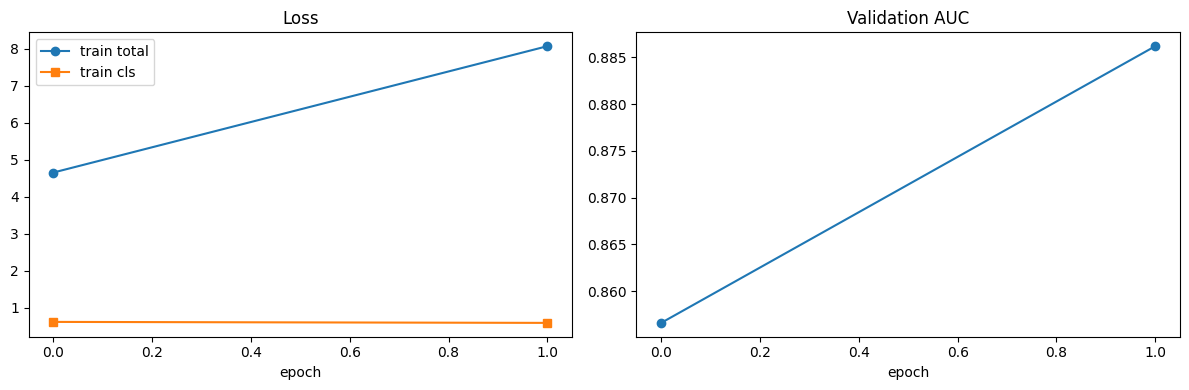

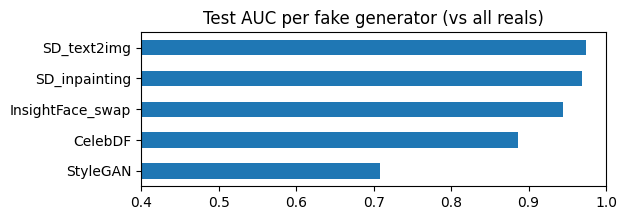

In [15]:
h = results["history"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_total, "o-", label="train total"); ax[0].plot(h.epoch, h.train_cls, "s-", label="train cls")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(h.epoch, h.val_auc, "o-", color="tab:blue"); ax[1].set_xlabel("epoch"); ax[1].set_title("Validation AUC")
plt.tight_layout(); plt.show()

pg = pd.Series(results["test_per_gen"]).sort_values()
pg.plot.barh(figsize=(6, max(2, 0.4 * len(pg))), title="Test AUC per fake generator (vs all reals)"); plt.xlim(0.4, 1.0); plt.show()

## 13. Inference on a new image or video

Raw inputs go through the same detect + align + JPEG q=95 normalisation as the training data. Video probabilities are averaged over sampled frames.

In [18]:
def load_detector(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    c = Config(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in ck["cfg"].items()})
    m = FADIDv2(c, len(ck["gen_to_idx"])).to(DEVICE)
    m.load_state_dict(ck["state"]); m.eval()
    return m, c, ck["thr"]

def _normalise_face(face_bgr, c):
    ok, enc = cv2.imencode(".jpg", face_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), c.jpeg_quality])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR)

@torch.no_grad()
def score_faces(m, c, faces):
    samples = [sample_from_aligned(_normalise_face(f, c), c, train=False) for f in faces]
    batch = {k: torch.stack([s[k] for s in samples]).to(DEVICE) for k in samples[0]}
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=c.amp and DEVICE.type == "cuda"):
        o = m(batch)
    return torch.sigmoid(o["logits"].float()).cpu().numpy()

def predict_image(m, c, thr, path):
    im = cv2.imread(path)
    face = align_face(im, c.aligned_size) if im is not None else None
    if face is None:
        return {"verdict": "NO FACE FOUND"}
    p = float(score_faces(m, c, [face])[0])
    return {"prob_fake": p, "verdict": "FAKE" if p > thr else "REAL"}

def predict_video(m, c, thr, path, n_frames=16):
    faces = [f for f in (align_face(fr, c.aligned_size) for fr in read_video_frames(path, n_frames)) if f is not None]
    if not faces:
        return {"verdict": "NO FACE FOUND"}
    ps = score_faces(m, c, faces)
    return {"prob_fake": float(ps.mean()), "frames_used": len(faces), "verdict": "FAKE" if ps.mean() > thr else "REAL"}

det_model, det_cfg, det_thr = load_detector(results["ckpt"])
print(predict_image(det_model, det_cfg, det_thr, "/content/work/Screenshot 2026-10-18 233858.png"))
# print(predict_video(det_model, det_cfg, det_thr, "/content/some_clip.mp4"))

Backbone vit_base_patch16_clip_224.openai: trainable 28,353,024 / 85,799,424 (33.0%), embed_dim=768
{'prob_fake': 0.5437719821929932, 'verdict': 'REAL'}


## 14. Honest-reporting checklist

* Report **zero-day AUC** (leave-generator-out), not only the seen-generator test AUC.
* Check per-dataset AUC against per-generator AUC. If in-dataset AUC is ~1.0 but cross-source AUC is low, the model is learning dataset identity, not forgery.
* Check the robustness table; real-world media is compressed and resized.
* Frames from the same video are never split across train/test here; keep it that way when adding sources.
* Ablate `alpha_adv=0`, `use_eye_branch=False` and `unfreeze_last_blocks=0` to find out which parts actually help on your data.